<a href="https://colab.research.google.com/github/BinaryRohit/YuvaIntern-Data-Science-Tasks/blob/main/Task4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import necessary core libraries
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer

# 1. Load the dataset
cancer_data = load_breast_cancer()

# 2. Convert to a Pandas DataFrame for easier manipulation
df = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)

# Add the target variable to the dataframe
# 0 = Malignant, 1 = Benign
df['target'] = cancer_data.target

# 3. Initial Inspection
print("--- Dataset Info ---")
df.info()

print("\n--- Missing Values Check ---")
print(df.isnull().sum().sum(), "total missing values")

print("\n--- Target Class Distribution ---")
print(df['target'].value_counts(normalize=True))

print("\n--- First 3 Rows ---")
display(df.head(3))

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separate features (X) and target (y)
X = df.drop(columns=['target'])
y = df['target']

# 2. Perform a Stratified Train-Test Split (80% train, 20% test)
# random_state ensures reproducibility for your GitHub notebook
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Initialize the StandardScaler
scaler = StandardScaler()

# 4. Fit on training data ONLY, then transform both train and test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Verify the shapes of our resulting arrays
print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_test shape: {X_test_scaled.shape}")
print(f"y_train distribution:\n{y_train.value_counts(normalize=True)}")

X_train shape: (455, 30)
X_test shape: (114, 30)
y_train distribution:
target
1    0.626374
0    0.373626
Name: proportion, dtype: float64


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# 1. Initialize the model
# random_state ensures reproducible results
log_reg = LogisticRegression(random_state=42)

# 2. Train (fit) the model on the scaled training data
log_reg.fit(X_train_scaled, y_train)

# 3. Predict class labels for the unseen test data
y_pred = log_reg.predict(X_test_scaled)

# 4. Predict probabilities (needed for ROC curve later)
# [:, 1] extracts the probability of the positive class (Benign)
y_pred_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

# 5. Evaluate the initial results textually
print("--- Logistic Regression Classification Report ---")
print(classification_report(y_test, y_pred, target_names=["Malignant (0)", "Benign (1)"]))

--- Logistic Regression Classification Report ---
               precision    recall  f1-score   support

Malignant (0)       0.98      0.98      0.98        42
   Benign (1)       0.99      0.99      0.99        72

     accuracy                           0.98       114
    macro avg       0.98      0.98      0.98       114
 weighted avg       0.98      0.98      0.98       114



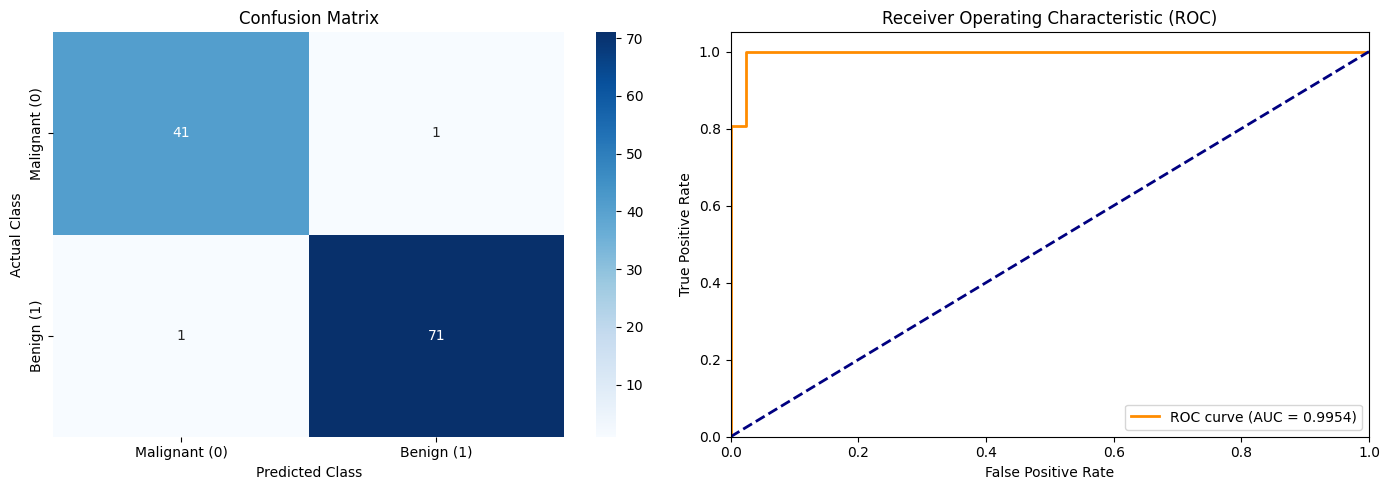

Visualizations successfully generated and saved as 'model_evaluation_metrics.png'.
Calculated AUC-ROC Score: 0.9954


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

# 1. Set up a matplotlib figure with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Plot 1: Confusion Matrix ---
# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot using Seaborn heatmap for a professional look
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Malignant (0)', 'Benign (1)'],
            yticklabels=['Malignant (0)', 'Benign (1)'])
axes[0].set_title('Confusion Matrix')
axes[0].set_ylabel('Actual Class')
axes[0].set_xlabel('Predicted Class')

# --- Plot 2: ROC Curve ---
# Calculate False Positive Rate (fpr), True Positive Rate (tpr) and Area Under Curve (AUC)
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--') # Baseline random guess
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")

# 2. Adjust layout, save the figure, and display
plt.tight_layout()
plt.savefig('model_evaluation_metrics.png', dpi=300)
plt.show()

# 3. Print confirmation
print("Visualizations successfully generated and saved as 'model_evaluation_metrics.png'.")
print(f"Calculated AUC-ROC Score: {roc_auc:.4f}")